# Feature Correlation and Vector Understanding

This notebook loads the cleaned dataset, explores correlations, highlights the strongest predictors of streams, and helps you choose feature vectors for modeling.

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('../data/spotify-2023-cleaned.csv')
df = pd.read_csv(DATA_PATH)
print(df.head())
print(f"\nShape: {df.shape}")

                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts      streams  in_apple_playlists  ...  bpm  key   mode  \
0                147  141381703.0          

In [3]:
# Keep numeric features only for correlation analysis
numeric_df = df.select_dtypes(include=[np.number])
print(numeric_df.columns.tolist())

['artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%']


In [5]:
# Correlation of every numeric feature with streams
if 'streams' in numeric_df.columns:
    corr = numeric_df.corr(numeric_only=True)['streams'].abs().sort_values(ascending=False)
    print("Top correlations with streams:")
    print(corr.head(20))
else:
    print("No 'streams' column found in the cleaned dataset.")

Top correlations with streams:
streams                 1.000000
in_spotify_playlists    0.789786
in_apple_playlists      0.771917
in_deezer_playlists     0.516312
in_apple_charts         0.320057
in_spotify_charts       0.245773
in_deezer_charts        0.228575
released_year           0.228506
artist_count            0.136436
speechiness_%           0.112302
danceability_%          0.105406
in_shazam_charts        0.050578
liveness_%              0.048337
instrumentalness_%      0.044902
valence_%               0.040810
energy_%                0.026050
released_month          0.024912
released_day            0.010587
acousticness_%          0.004483
bpm                     0.002438
Name: streams, dtype: float64


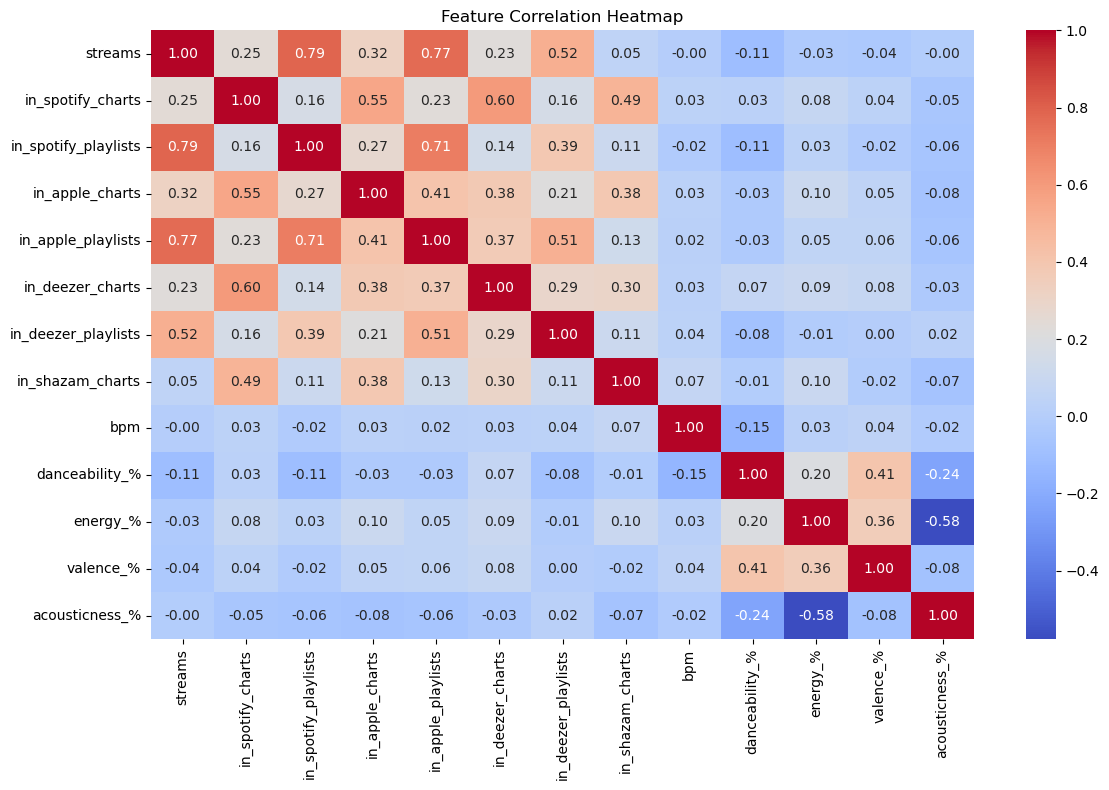

In [6]:
# Heatmap for the most relevant features
feature_subset = ['streams', 'in_spotify_charts', 'in_spotify_playlists', 'in_apple_charts', 'in_apple_playlists', 'in_deezer_charts', 'in_deezer_playlists', 'in_shazam_charts', 'bpm', 'danceability_%', 'energy_%', 'valence_%', 'acousticness_%']
feature_subset = [col for col in feature_subset if col in df.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(df[feature_subset].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# Heatmap Takeaways
1) The strongest relationships with streams are platform presence features, especially playlist counts.
2) `in_spotify_playlists` and `in_apple_playlists` stand out as the most predictive non-stream features.
3) Playlist-related metrics are more strongly correlated with streams than chart appearance metrics.
4) Chart placement features (`in_spotify_charts`, `in_apple_charts`, `in_deezer_charts`, `in_shazam_charts`) still show positive correlations, but much weaker than playlist features.
5) `in_deezer_playlists` also has a meaningful positive relationship, though below Spotify and Apple playlists.
6) Audio attributes like `bpm`, `danceability_%`, `energy_%`, `valence_%`, and `acousticness_%` have very low correlation with streams, suggesting they are less useful for predicting popularity in this dataset.
7) This heatmap reinforces the idea that platform distribution and playlist visibility are more important for stream count than basic song-level audio features.

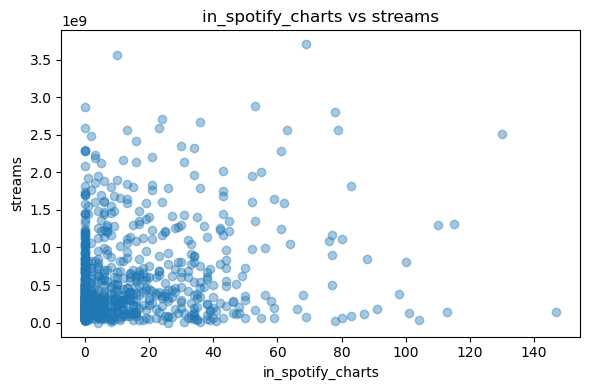

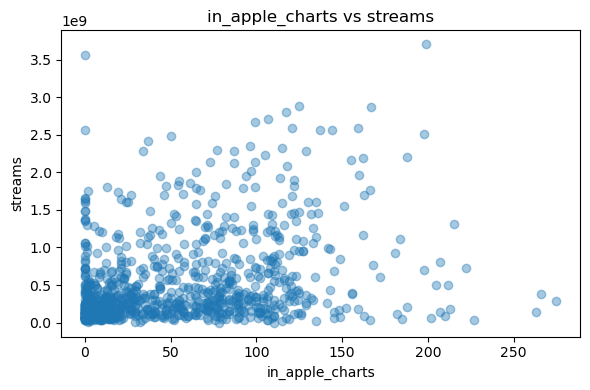

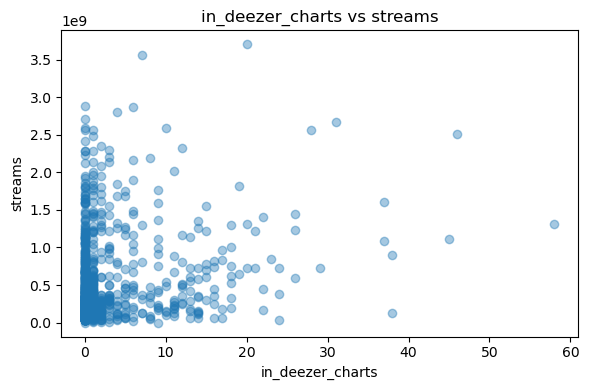

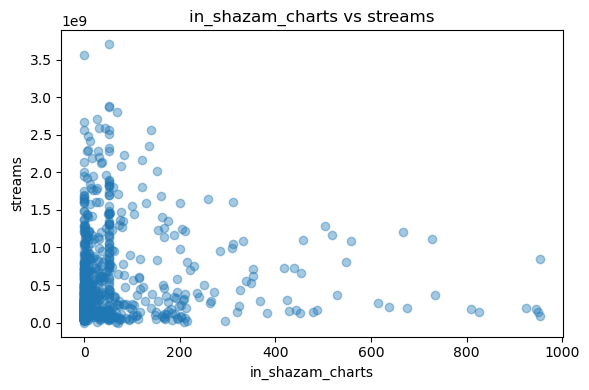

In [9]:
# Quick understanding of relationships with the strongest platform-based features
for col in ['in_spotify_charts', 'in_apple_charts', 'in_deezer_charts', 'in_shazam_charts']:
    if col in df.columns:
        plt.figure(figsize=(6, 4))
        plt.scatter(df[col], df['streams'], alpha=0.4)
        plt.xlabel(col)
        plt.ylabel('streams')
        plt.title(f'{col} vs streams')
        plt.tight_layout()
        plt.show()

The scatter plots show a loose positive relationship between chart presence and streams, but with a lot of spread.

- For `in_spotify_charts` vs `streams`, there is a weak upward trend: tracks with more Spotify chart entries often have higher streams, but many tracks with few or no chart entries still have very high stream counts.
- For `in_apple_charts` vs `streams`, the pattern is similar: higher Apple chart counts are associated with higher streams, yet the points are widely scattered and not tightly clustered along a line.
- For `in_deezer_charts` vs `streams`, the relationship is much weaker; the points form a broad cloud and chart count explains little of the stream variation.
- For `in_shazam_charts` vs `streams`, the scatter is almost flat, with most points at low Shazam chart counts and streams varying widely.

Overall, the plots show a lot of variability and only modest positive trends for the chart-related features.

In [11]:
# Recommended feature vectors for modeling
strong_feature_vector = [
    'in_spotify_playlists',
    'in_spotify_charts',
    'in_apple_playlists',
    'in_apple_charts',
    'in_deezer_charts',
    'in_deezer_playlists',
    'in_shazam_charts'
]
strong_feature_vector = [col for col in strong_feature_vector if col in df.columns]

print("Strong feature vector candidates:")
print(strong_feature_vector)

Strong feature vector candidates:
['in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_charts', 'in_deezer_playlists', 'in_shazam_charts']


# Feature Correlation and Vector Understanding

This notebook loads the cleaned dataset, explores correlations, highlights the strongest predictors of streams, and helps you choose feature vectors for modeling.

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('../data/spotify-2023-cleaned.csv')
df = pd.read_csv(DATA_PATH)
print(df.head())
print(f"\nShape: {df.shape}")


                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts      streams  in_apple_playlists  ...  bpm  key   mode  \
0                147  141381703.0          

In [13]:
# Keep numeric features only for correlation analysis
numeric_df = df.select_dtypes(include=[np.number])
print(numeric_df.columns.tolist())


['artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%']


In [14]:
# Correlation of every numeric feature with streams
if 'streams' in numeric_df.columns:
    corr = numeric_df.corr(numeric_only=True)['streams'].abs().sort_values(ascending=False)
    print("Top correlations with streams:")
    print(corr.head(20))
else:
    print("No 'streams' column found in the cleaned dataset.")


Top correlations with streams:
streams                 1.000000
in_spotify_playlists    0.789786
in_apple_playlists      0.771917
in_deezer_playlists     0.516312
in_apple_charts         0.320057
in_spotify_charts       0.245773
in_deezer_charts        0.228575
released_year           0.228506
artist_count            0.136436
speechiness_%           0.112302
danceability_%          0.105406
in_shazam_charts        0.050578
liveness_%              0.048337
instrumentalness_%      0.044902
valence_%               0.040810
energy_%                0.026050
released_month          0.024912
released_day            0.010587
acousticness_%          0.004483
bpm                     0.002438
Name: streams, dtype: float64


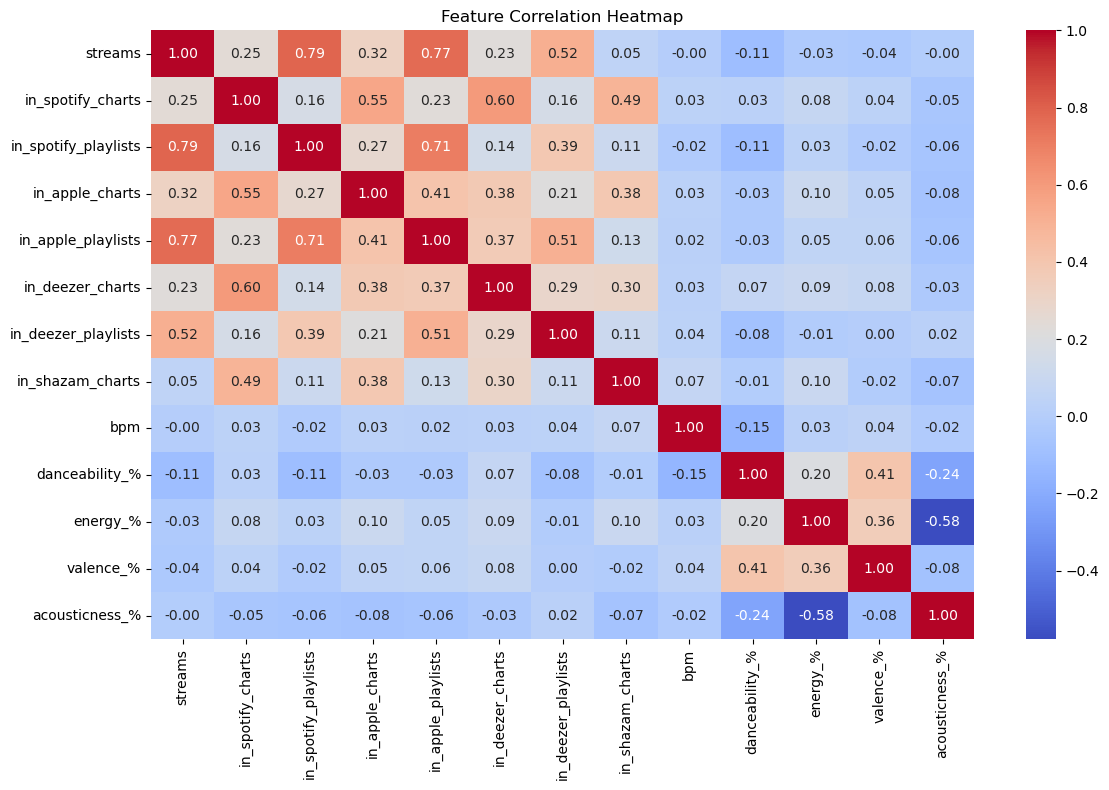

In [15]:
# Heatmap for the most relevant features
feature_subset = ['streams', 'in_spotify_charts', 'in_spotify_playlists', 'in_apple_charts', 'in_apple_playlists', 'in_deezer_charts', 'in_deezer_playlists', 'in_shazam_charts', 'bpm', 'danceability_%', 'energy_%', 'valence_%', 'acousticness_%']
feature_subset = [col for col in feature_subset if col in df.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(df[feature_subset].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


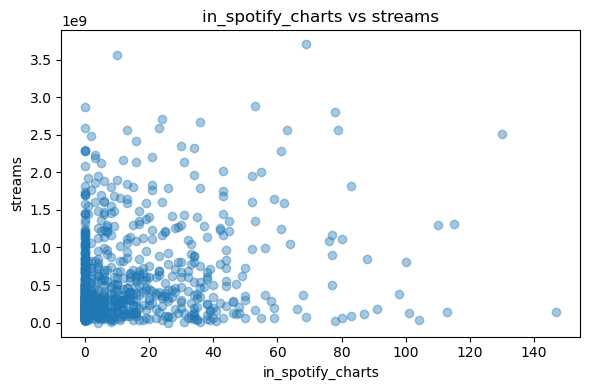

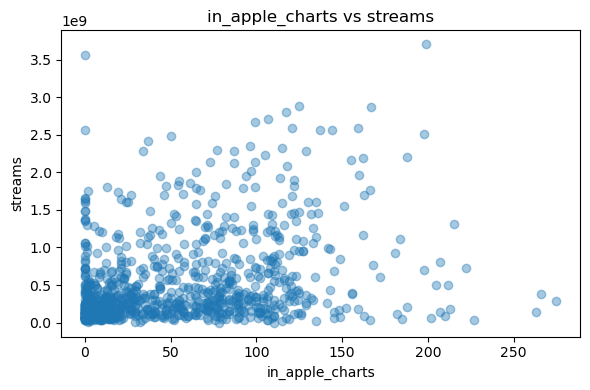

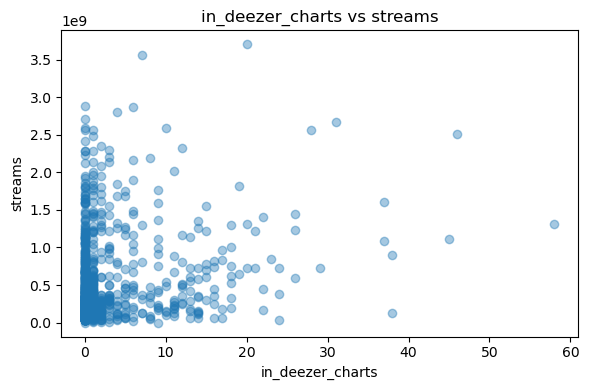

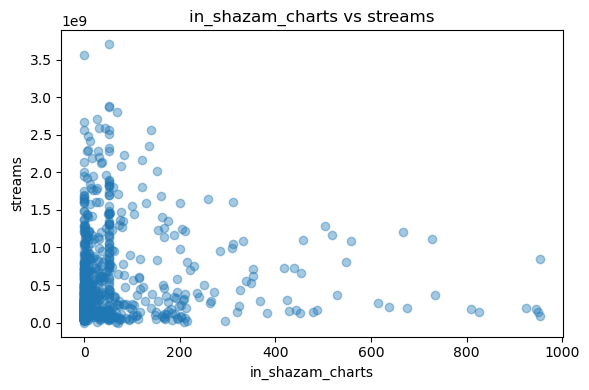

In [16]:
# Quick understanding of relationships with the strongest platform-based features
for col in ['in_spotify_charts', 'in_apple_charts', 'in_deezer_charts', 'in_shazam_charts']:
    if col in df.columns:
        plt.figure(figsize=(6, 4))
        plt.scatter(df[col], df['streams'], alpha=0.4)
        plt.xlabel(col)
        plt.ylabel('streams')
        plt.title(f'{col} vs streams')
        plt.tight_layout()
        plt.show()


In [17]:
# Recommended feature vectors for modeling
strong_feature_vector = [
    'in_spotify_playlists',
    'in_spotify_charts',
    'in_apple_playlists',
    'in_apple_charts',
    'in_deezer_charts',
    'in_deezer_playlists',
    'in_shazam_charts'
]
strong_feature_vector = [col for col in strong_feature_vector if col in df.columns]

print("Strong feature vector candidates:")
print(strong_feature_vector)


Strong feature vector candidates:
['in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_charts', 'in_deezer_playlists', 'in_shazam_charts']
